In [1]:
import pandas as pd 
import numpy as np

df = pd.read_csv('Pareto_data.csv')
df

,Formula,lat,M_s,T_C,Pugh,Cauchy,norm_M_s,norm_T_C,norm_Pugh,norm_Cauchy,HV
0,Sc0.111Cr0.157Fe0.297Cu0.098Zn0.337,0,0.155816,469.807397,1.611308,-19.139812,-0.624345,-0.307798,-2.861104,-3.713955,0.000000
1,Sc0.183Ti0.090Fe0.302Cu0.065Zn0.360,0,0.190242,772.325259,2.334783,10.767347,-0.484298,0.206004,-0.496042,-1.266889,5.193025
2,Sc0.155Cr0.140Fe0.217Co0.101Zn0.387,0,0.140976,358.365890,2.040936,3.951058,-0.684715,-0.497072,-1.456637,-1.824612,0.829389
3,Sc0.170Mn0.050Fe0.211Co0.250Cu0.319,0,0.336122,1033.801824,2.453179,22.472381,0.109146,0.650101,-0.108999,-0.309159,20.881547
4,Sc0.218V0.061Fe0.251Cu0.189Zn0.281,0,0.154184,722.086639,2.340773,10.219456,-0.630981,0.120678,-0.476460,-1.311718,3.979707
...,...,...,...,...,...,...,...,...,...,...,...
161,Sc0.055Ti0.042Fe0.162Co0.580Cu0.161,0,0.472041,1514.301301,2.588095,36.202949,0.662072,1.466191,0.332045,0.814305,68.134822
162,Sc0.083Fe0.273Co0.250Ni0.149Cu0.245,0,0.413497,1110.941674,2.810321,35.539348,0.423913,0.781117,1.058509,0.760008,53.484123
163,Sc0.081Fe0.222Co0.148Ni0.254Cu0.295,1,0.311606,586.575047,2.855925,33.776507,0.009415,-0.109477,1.207589,0.615769,22.544914
164,Sc0.038V0.012Fe0.329Co0.160Cu0.461,1,0.382275,996.130126,3.039644,38.526231,0.296901,0.586119,1.808175,1.004401,56.484697


In [2]:
# def sort_every_X_steps(df, column_to_sort, step=50):
#     chunks = [df.iloc[i:i+step] for i in range(1, len(df), step)]  # Split into chunks of 50 rows
#     # sorted_chunks = [chunk.sort_values(by=column_to_sort).reset_index(drop=True) for chunk in chunks]
#     sorted_chunks = [chunk.sort_index(ascending=False) for chunk in chunks]
#     return pd.concat(sorted_chunks, ignore_index=True)

# df = sort_every_X_steps(df, 'HV', 10)
# df

In [3]:
# Calculate average and standard deviation for every 10 rows
step = 10
grouped_stats = df[['norm_M_s', 'norm_T_C', 'norm_Pugh', 'norm_Cauchy', 'HV']].groupby(df.index // step).agg(['mean', 'std'])

# Extract the means and standard deviations
means = grouped_stats.xs('mean', level=1, axis=1)
stds = grouped_stats.xs('std', level=1, axis=1)

In [4]:
# !pip3 install seaborn --user

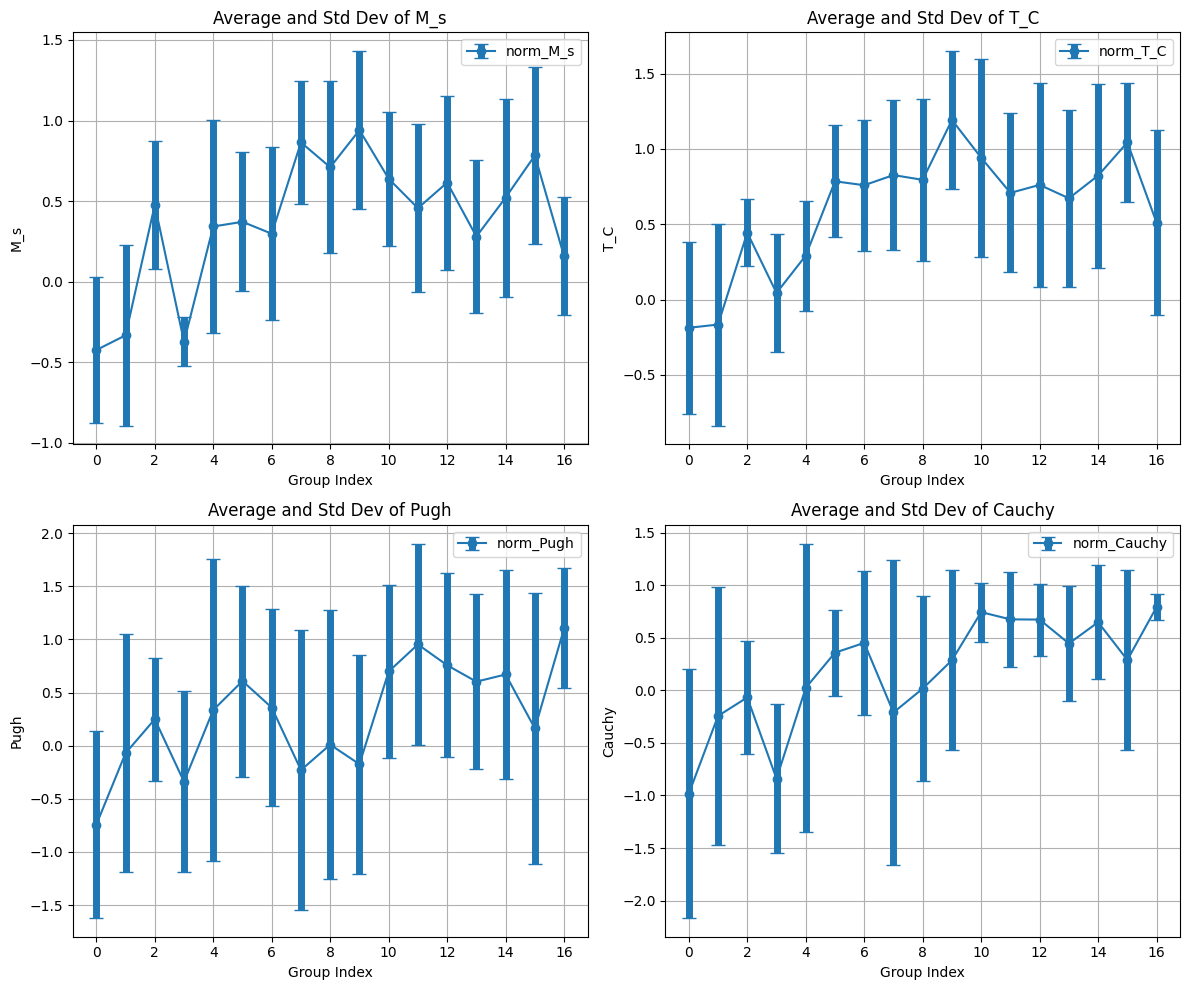

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
# Create a 2x2 subplot for the data
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Column names for iteration
columns = means.columns
titles = ['M_s', 'T_C', 'Pugh', 'Cauchy']
# titles = columns_to_normalize

# Plot each column in the appropriate subplot
for idx, ax in enumerate(axs.flatten()):
    column = columns[idx]
    ax.errorbar(means.index, means[column], yerr=stds[column], fmt='o-', capsize=5, label=column, elinewidth=5)
    # ax.fill_between(means.index, means[column] - stds[column], means[column] + stds[column], color='gray', alpha=0.3, label='Error Band')
    # sns.pointplot(data=df, x='Group', y='Value', capsize=0.2, errwidth=1, ci='sd', color='b')
    ax.set_title(f"Average and Std Dev of {titles[idx]}")
    ax.set_xlabel("Group Index")
    ax.set_ylabel(titles[idx])
    ax.grid()
    ax.legend()

# Adjust layout
plt.tight_layout()
plt.show()

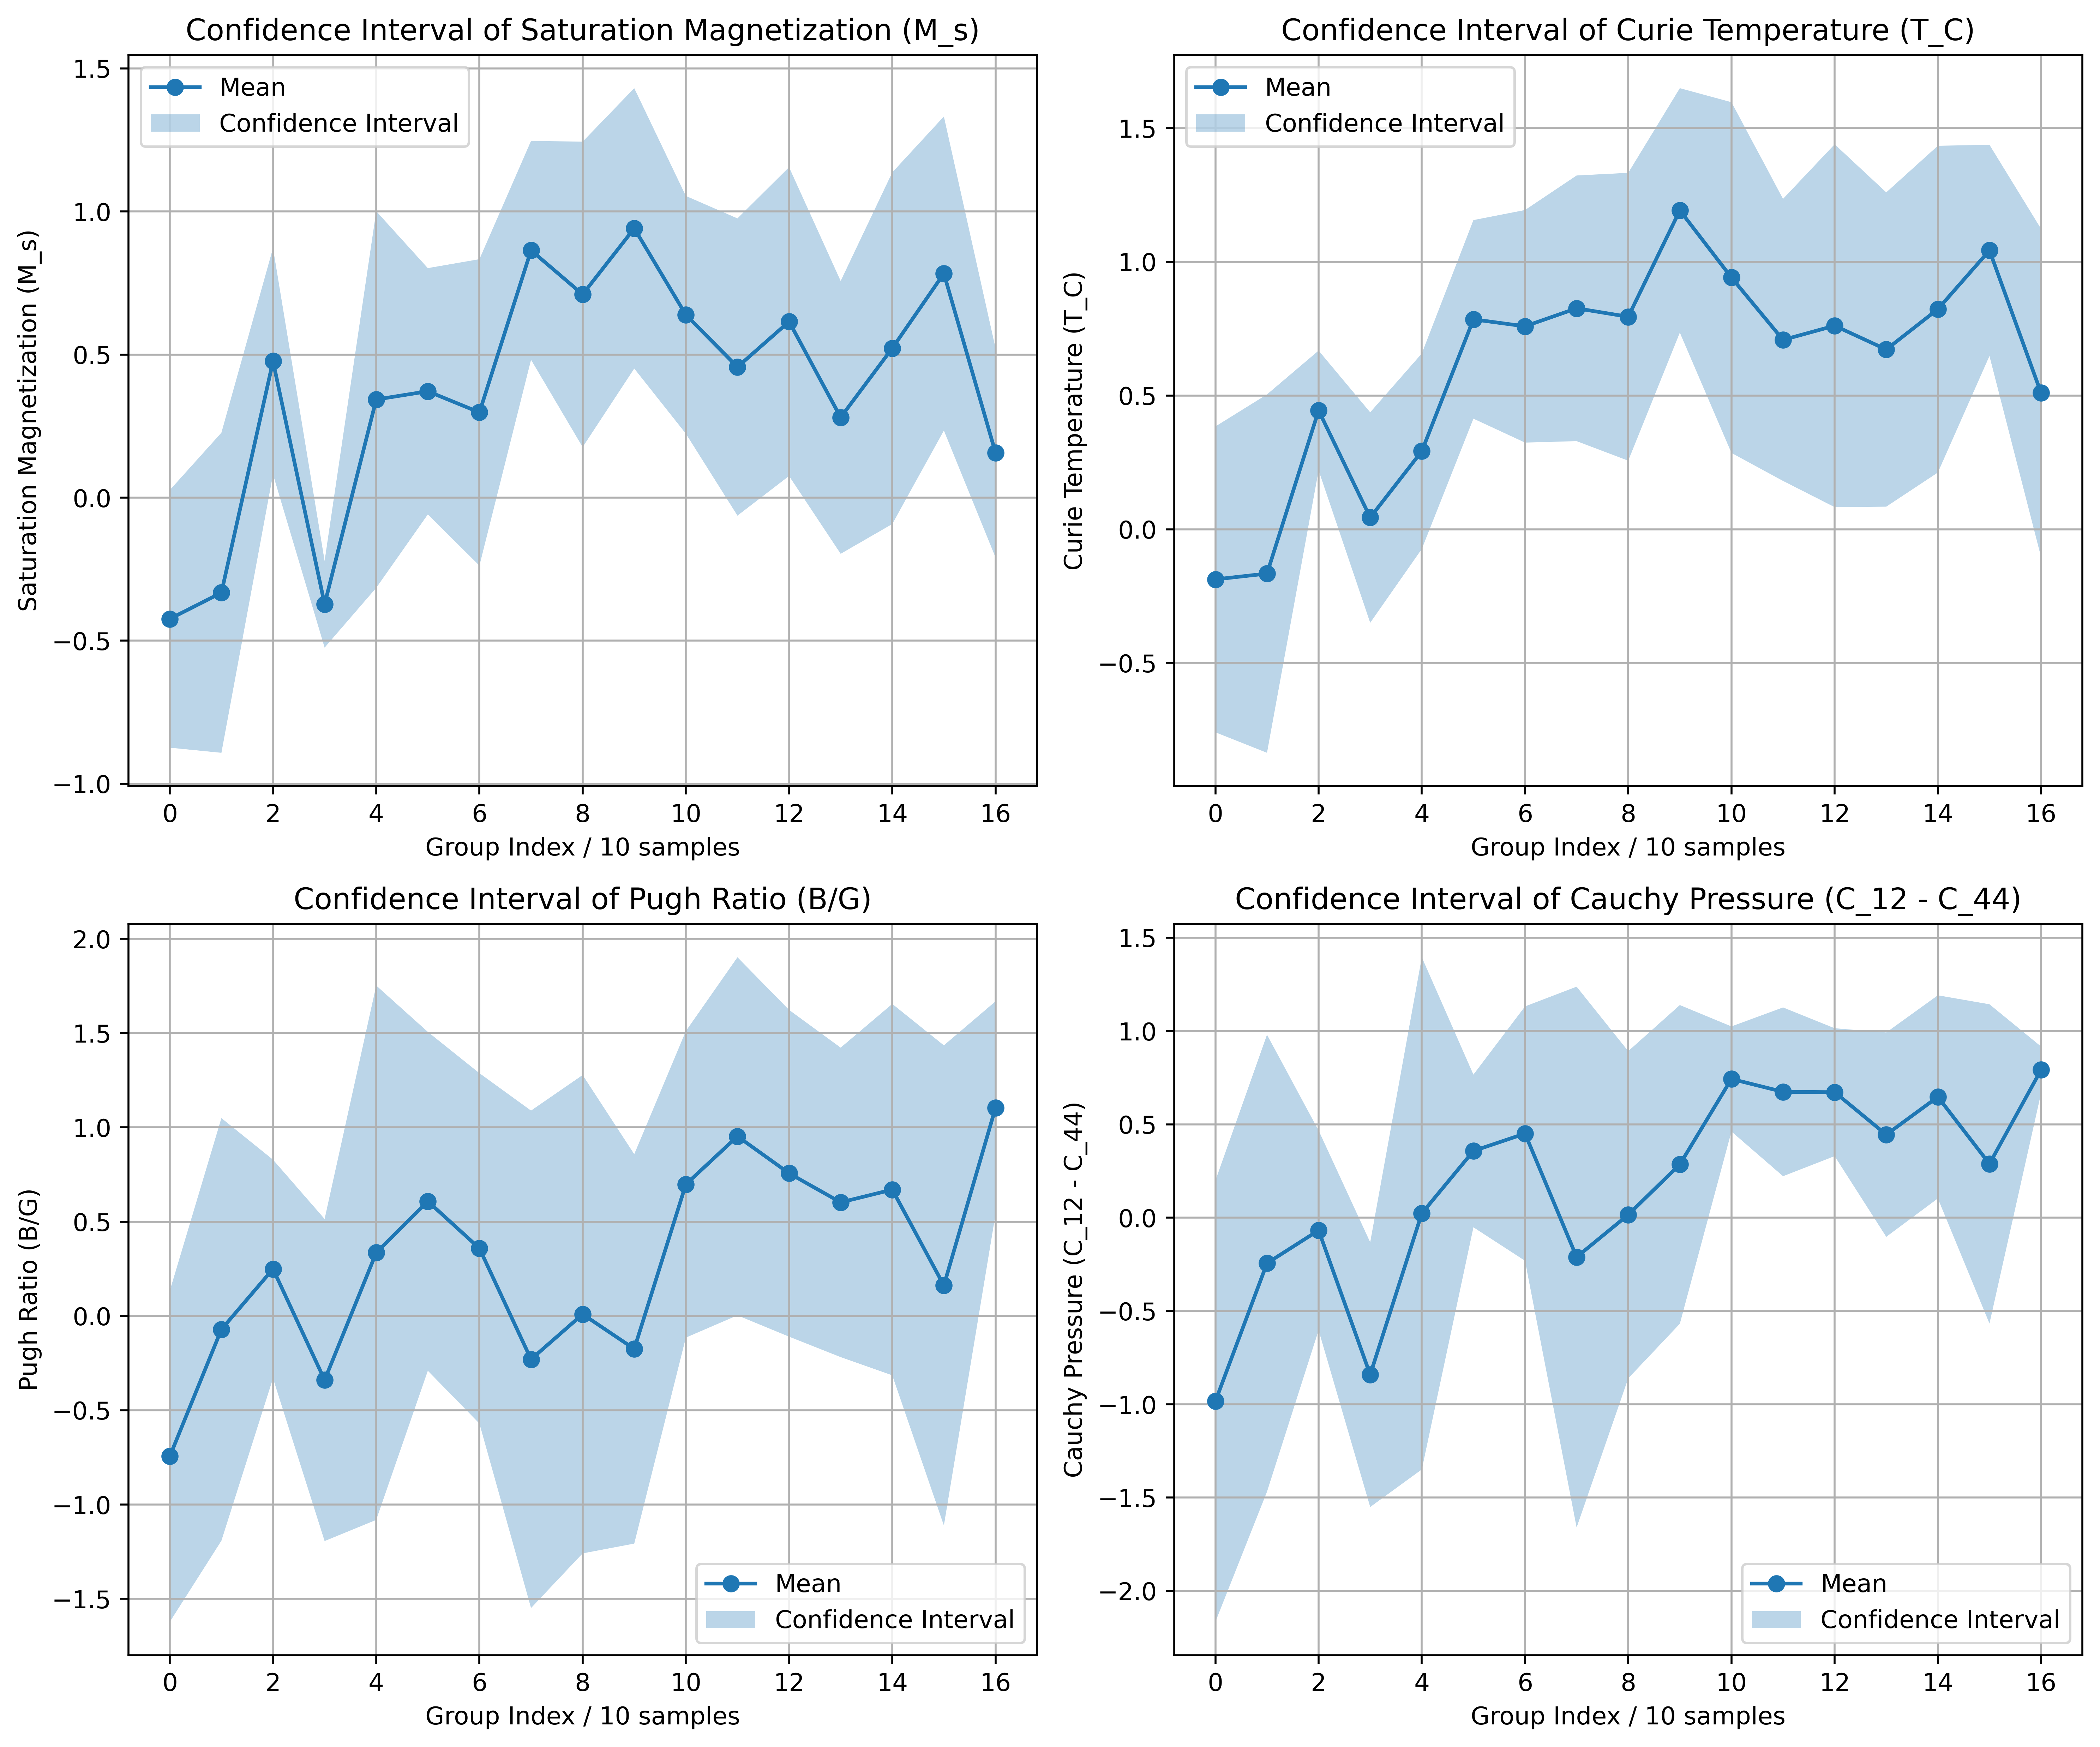

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# Create a 2x2 subplot for the data
fig, axs = plt.subplots(2, 2, figsize=(12, 10), dpi=500)
titles = ['Saturation Magnetization (M_s)', 'Curie Temperature (T_C)', 'Pugh Ratio (B/G)', 'Cauchy Pressure (C_12 - C_44)']

# Column names for iteration
columns = means.columns
# titles = ['M_s', 'T_C', 'Pugh', 'Cauchy']
# titles = columns_to_normalize

# Plot each column in the appropriate subplot
for idx, ax in enumerate(axs.flatten()):
    column = columns[idx]
    ax.plot(means.index, means[column], marker='o', label='Mean')
    ax.fill_between(
        means.index,
        means[column] - stds[column],
        means[column] + stds[column],
        alpha=0.3,
        label='Confidence Interval'
    )
    ax.set_title(f'Confidence Interval of {titles[idx]}')
    ax.set_xlabel('Group Index / 10 samples')
    ax.set_ylabel(titles[idx])
    ax.grid()
    ax.legend()

# Adjust layout
plt.tight_layout()
plt.show()

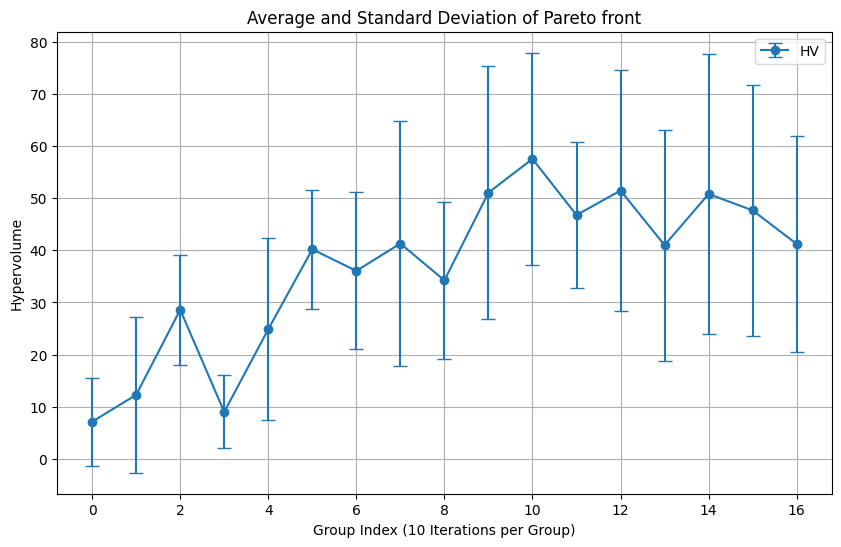

In [7]:
plt.figure(figsize=(10, 6))
plt.errorbar(means.index, means['HV'], yerr=stds['HV'], fmt='o-', capsize=5, label='HV')
plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Group Index (10 Iterations per Group)")
plt.ylabel('Hypervolume')
plt.legend()
plt.grid()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6), dpi=500)
# plt.errorbar(means.index, means['pareto'], yerr=stds['pareto'], fmt='o-', capsize=5, label='pareto')
plt.plot(means.index, means['HV'], marker='o', label='Mean')
plt.fill_between(
    means.index,
    means['HV'] - stds['HV'],
    means['HV'] + stds['HV'],
    alpha=0.3,
    label='Confidence Interval'
)
plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Group Index/10 samples")
plt.ylabel('Pareto front')
plt.legend()
plt.grid()
plt.show()
# ax.plot(means.index, means[column], marker='o', label='Mean')
# ax.fill_between(
#     means.index,
#     means[column] - stds[column],
#     means[column] + stds[column],
#     alpha=0.3,
#     label='Confidence Interval'
# )

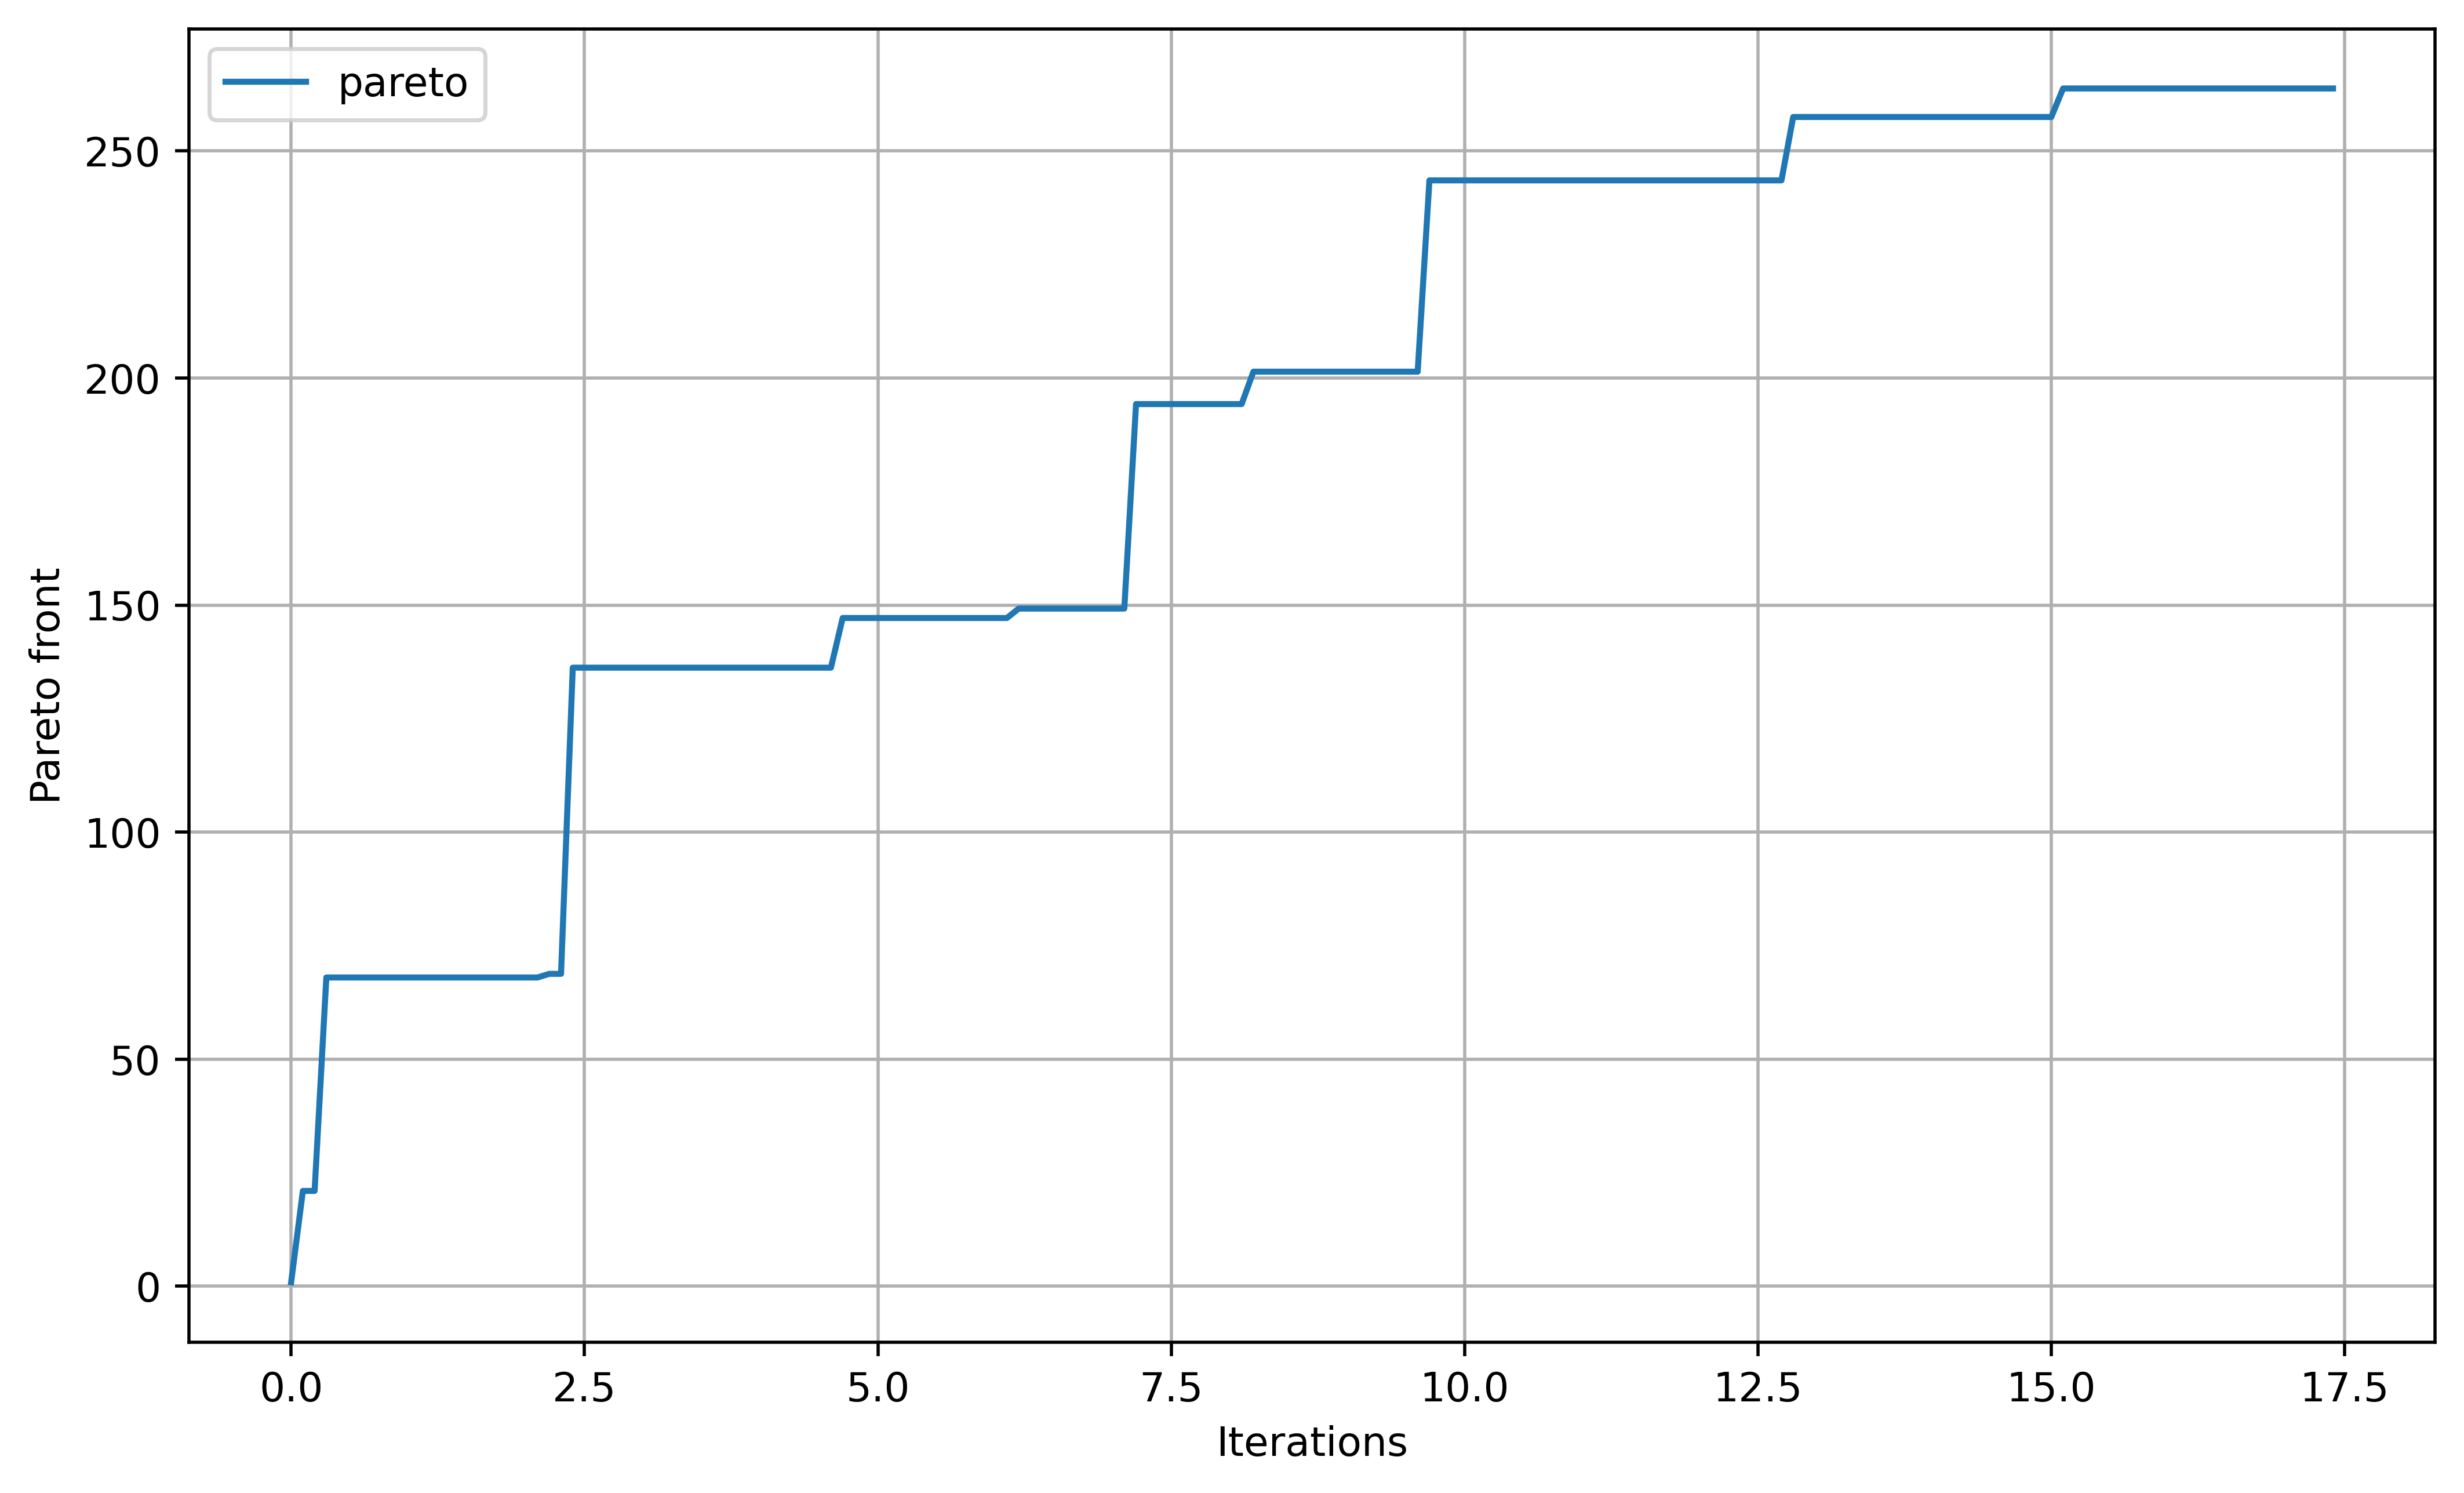

In [ ]:
df['pareto'] = df['HV'].expanding().max()
plt.figure(figsize=(10, 6), dpi=500)
plt.errorbar(df.index/10, df['pareto'], fmt='-', capsize=1, label='pareto')
# plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Iterations")
plt.ylabel('Pareto front')
plt.legend()
plt.grid()
plt.savefig('hv_convergence.png')
plt.show()

<Figure size 3000x2000 with 0 Axes>

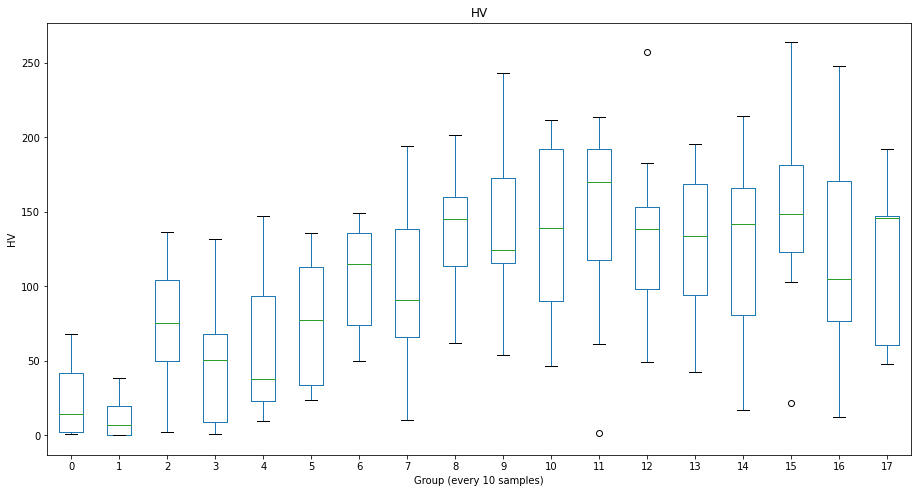

In [ ]:
data = pd.read_csv('Pareto_data.csv')
data['Group'] = (data.index // 10)
# fig = plt.figure(figsize=(15, 8), dpi=500)
plt.figure(dpi=500)
data.boxplot(column='HV', by='Group', grid=False, showfliers=True, figsize=(15, 8))

# plt.title('Boxplot of HV grouped by every 10 steps')
plt.suptitle('')  # Remove default subtitle
plt.xlabel('Group (every 10 samples)')
plt.ylabel('HV')
plt.savefig('HV_box.png')
plt.show()

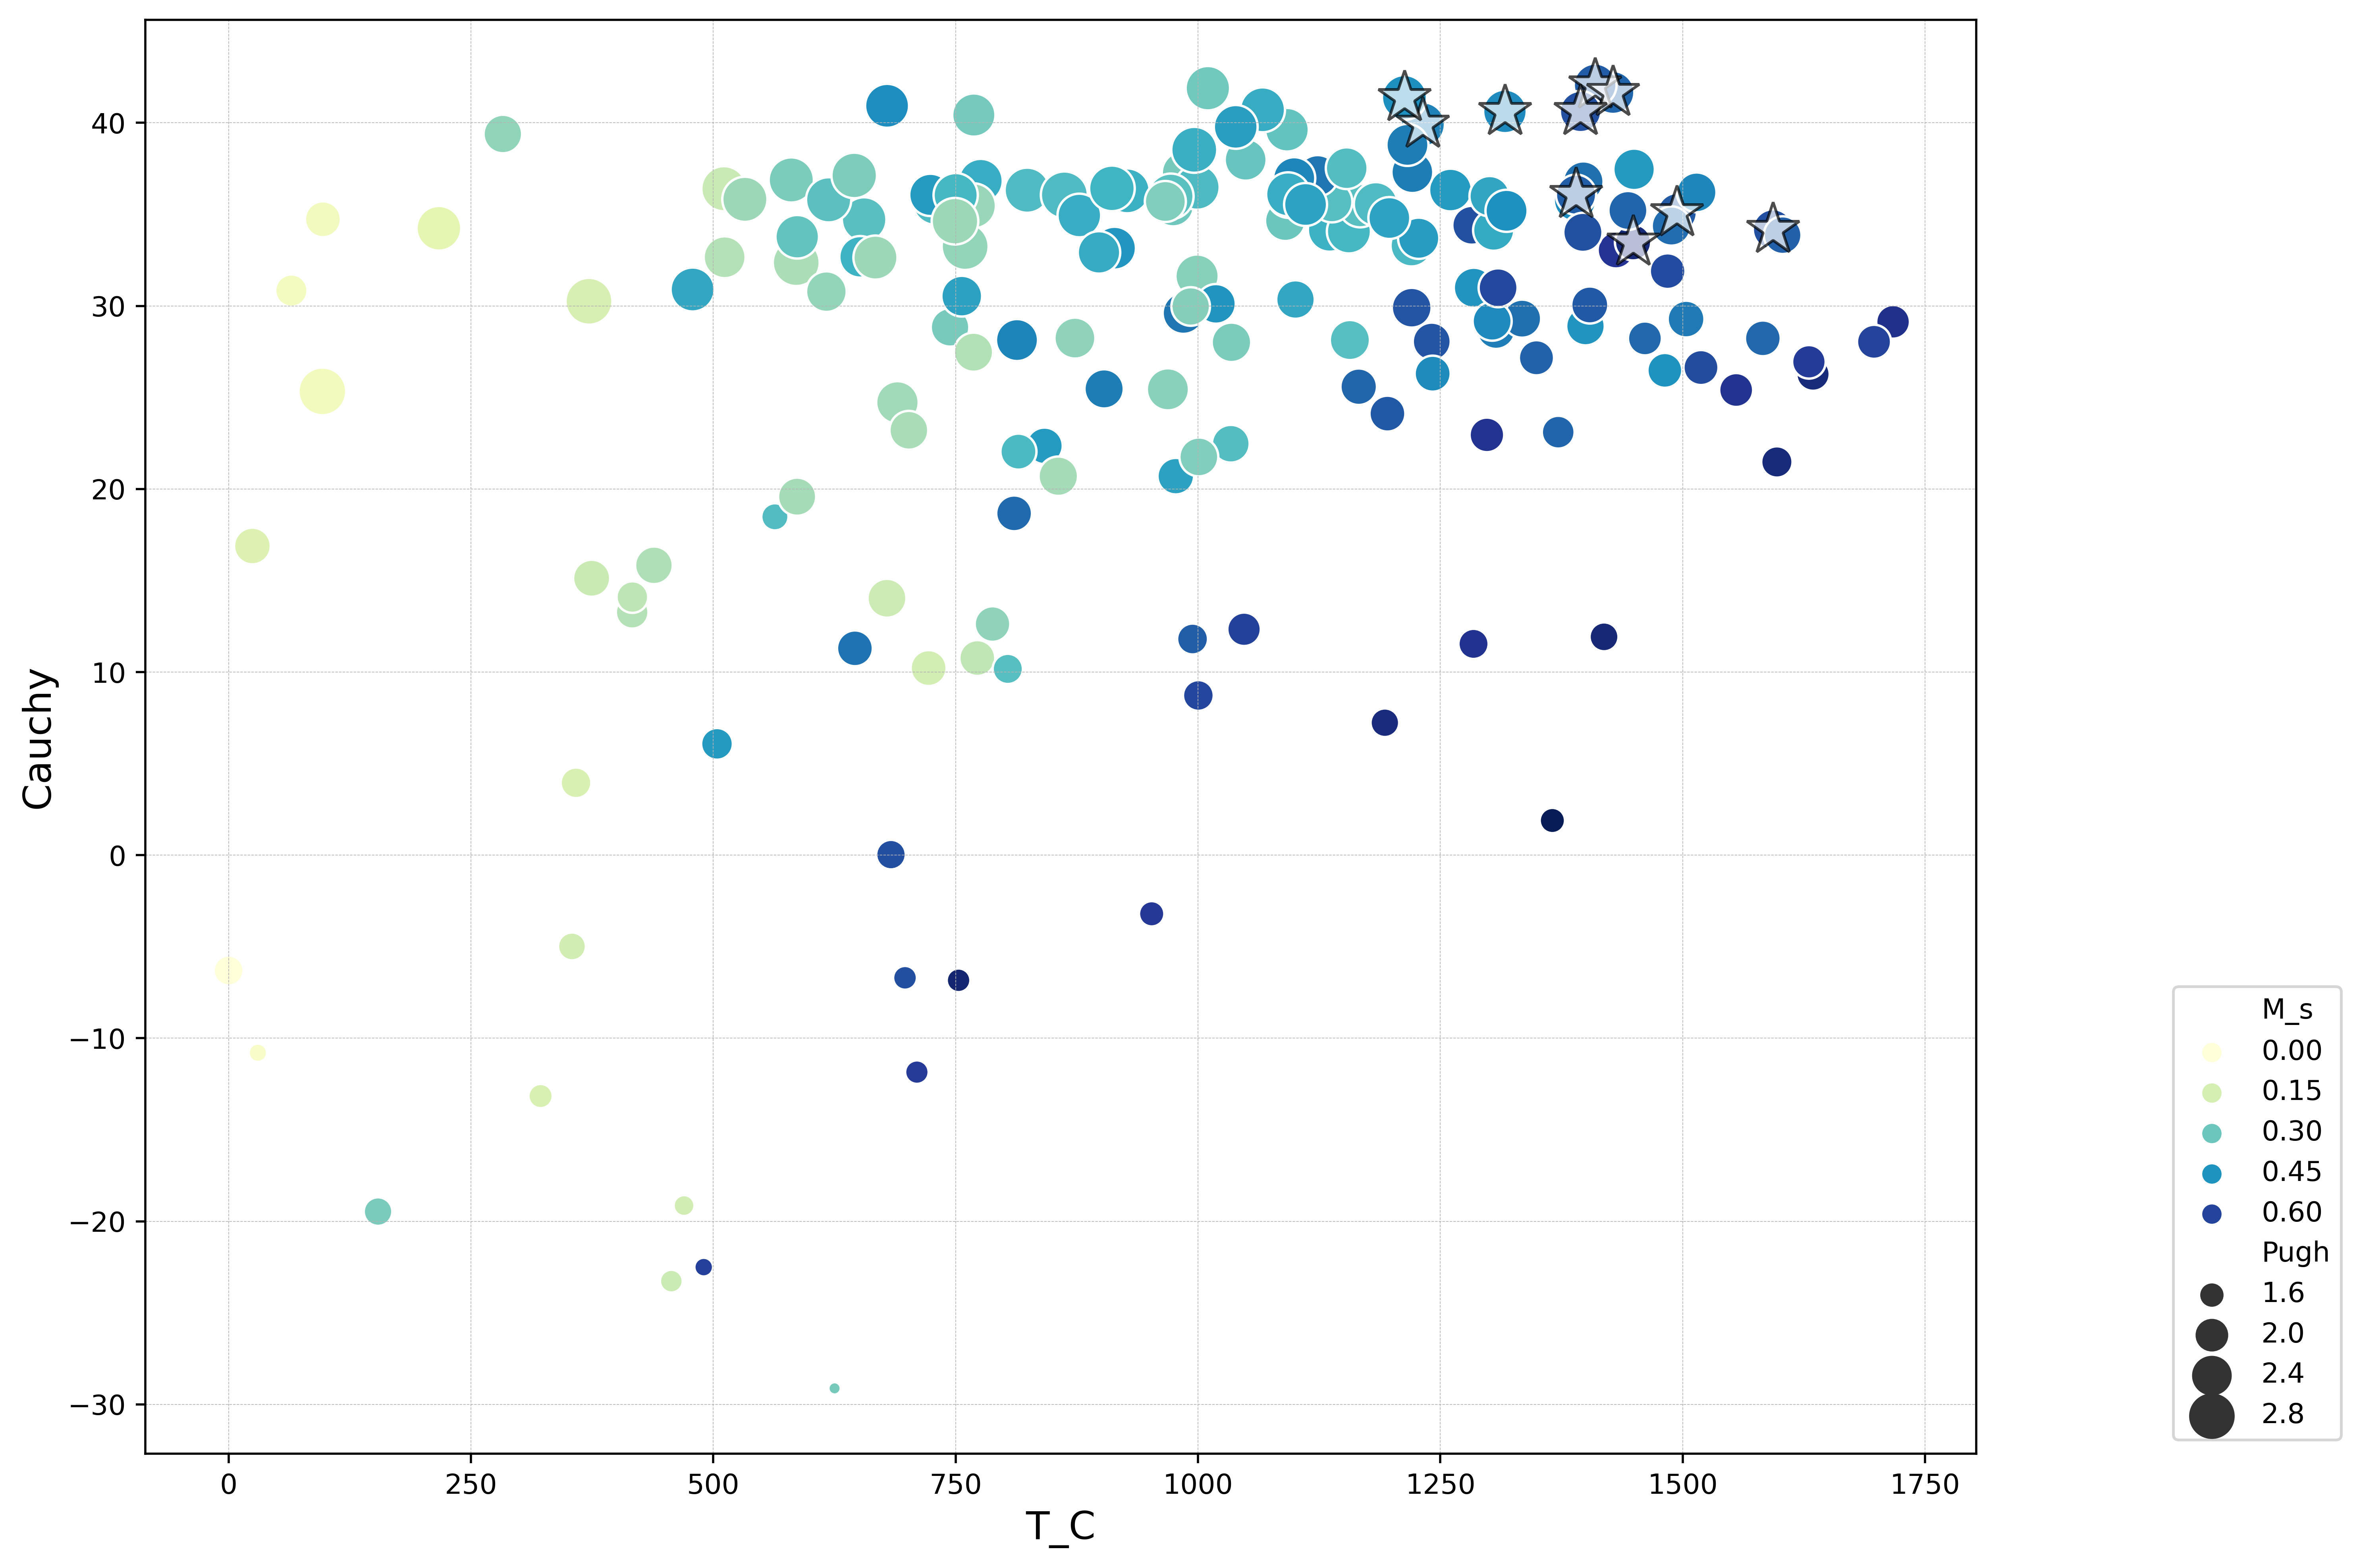

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
data = pd.read_csv('Pareto_data.csv')
pareto_points = data.sort_values(by=['HV'],ascending=False).reset_index(drop=True).head(10)
# 设置图片大小和分辨率
plt.figure(figsize=(12, 8), dpi=500)

# 绘制散点图
ax = sns.scatterplot(
    data=data, 
    x="T_C", 
    y="Cauchy", 
    hue="M_s", 
    size="Pugh", 
    # palette='RdYlBu_r',
    palette = 'YlGnBu',
    sizes=(20, 300)
    # hue_norm=(data['M_s'].min() - (data['M_s'].max() - data['M_s'].min()) * 0.1, data['M_s'].max() + (data['M_s'].max() - data['M_s'].min()) * 0.1),  # 增加hue区分度
    # size_norm=(data['Pugh'].min() - (data['Pugh'].max() - data['Pugh'].min()) * 0.1, data['Pugh'].max() + (data['Pugh'].max() - data['Pugh'].min()) * 0.1)  # 增加size区分度

)

# 设置标签
ax.set_xlabel('T_C', fontsize=14)
ax.set_ylabel('Cauchy', fontsize=14)
ax.grid(linestyle='--', linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)

# 标记Pareto前沿的10个点
# pareto_points = data.nlargest(10, 'Pugh')  # 按Pugh列选择前10个点
for idx, row in pareto_points.iterrows():
    ax.plot(
        row['T_C'], 
        row['Cauchy'], 
        marker='*', 
        markersize=20, 
        color='white',
        alpha=0.7, 
        markeredgecolor='black', 
        markeredgewidth=1.
    )

# 显示图表
plt.tight_layout()
plt.show()



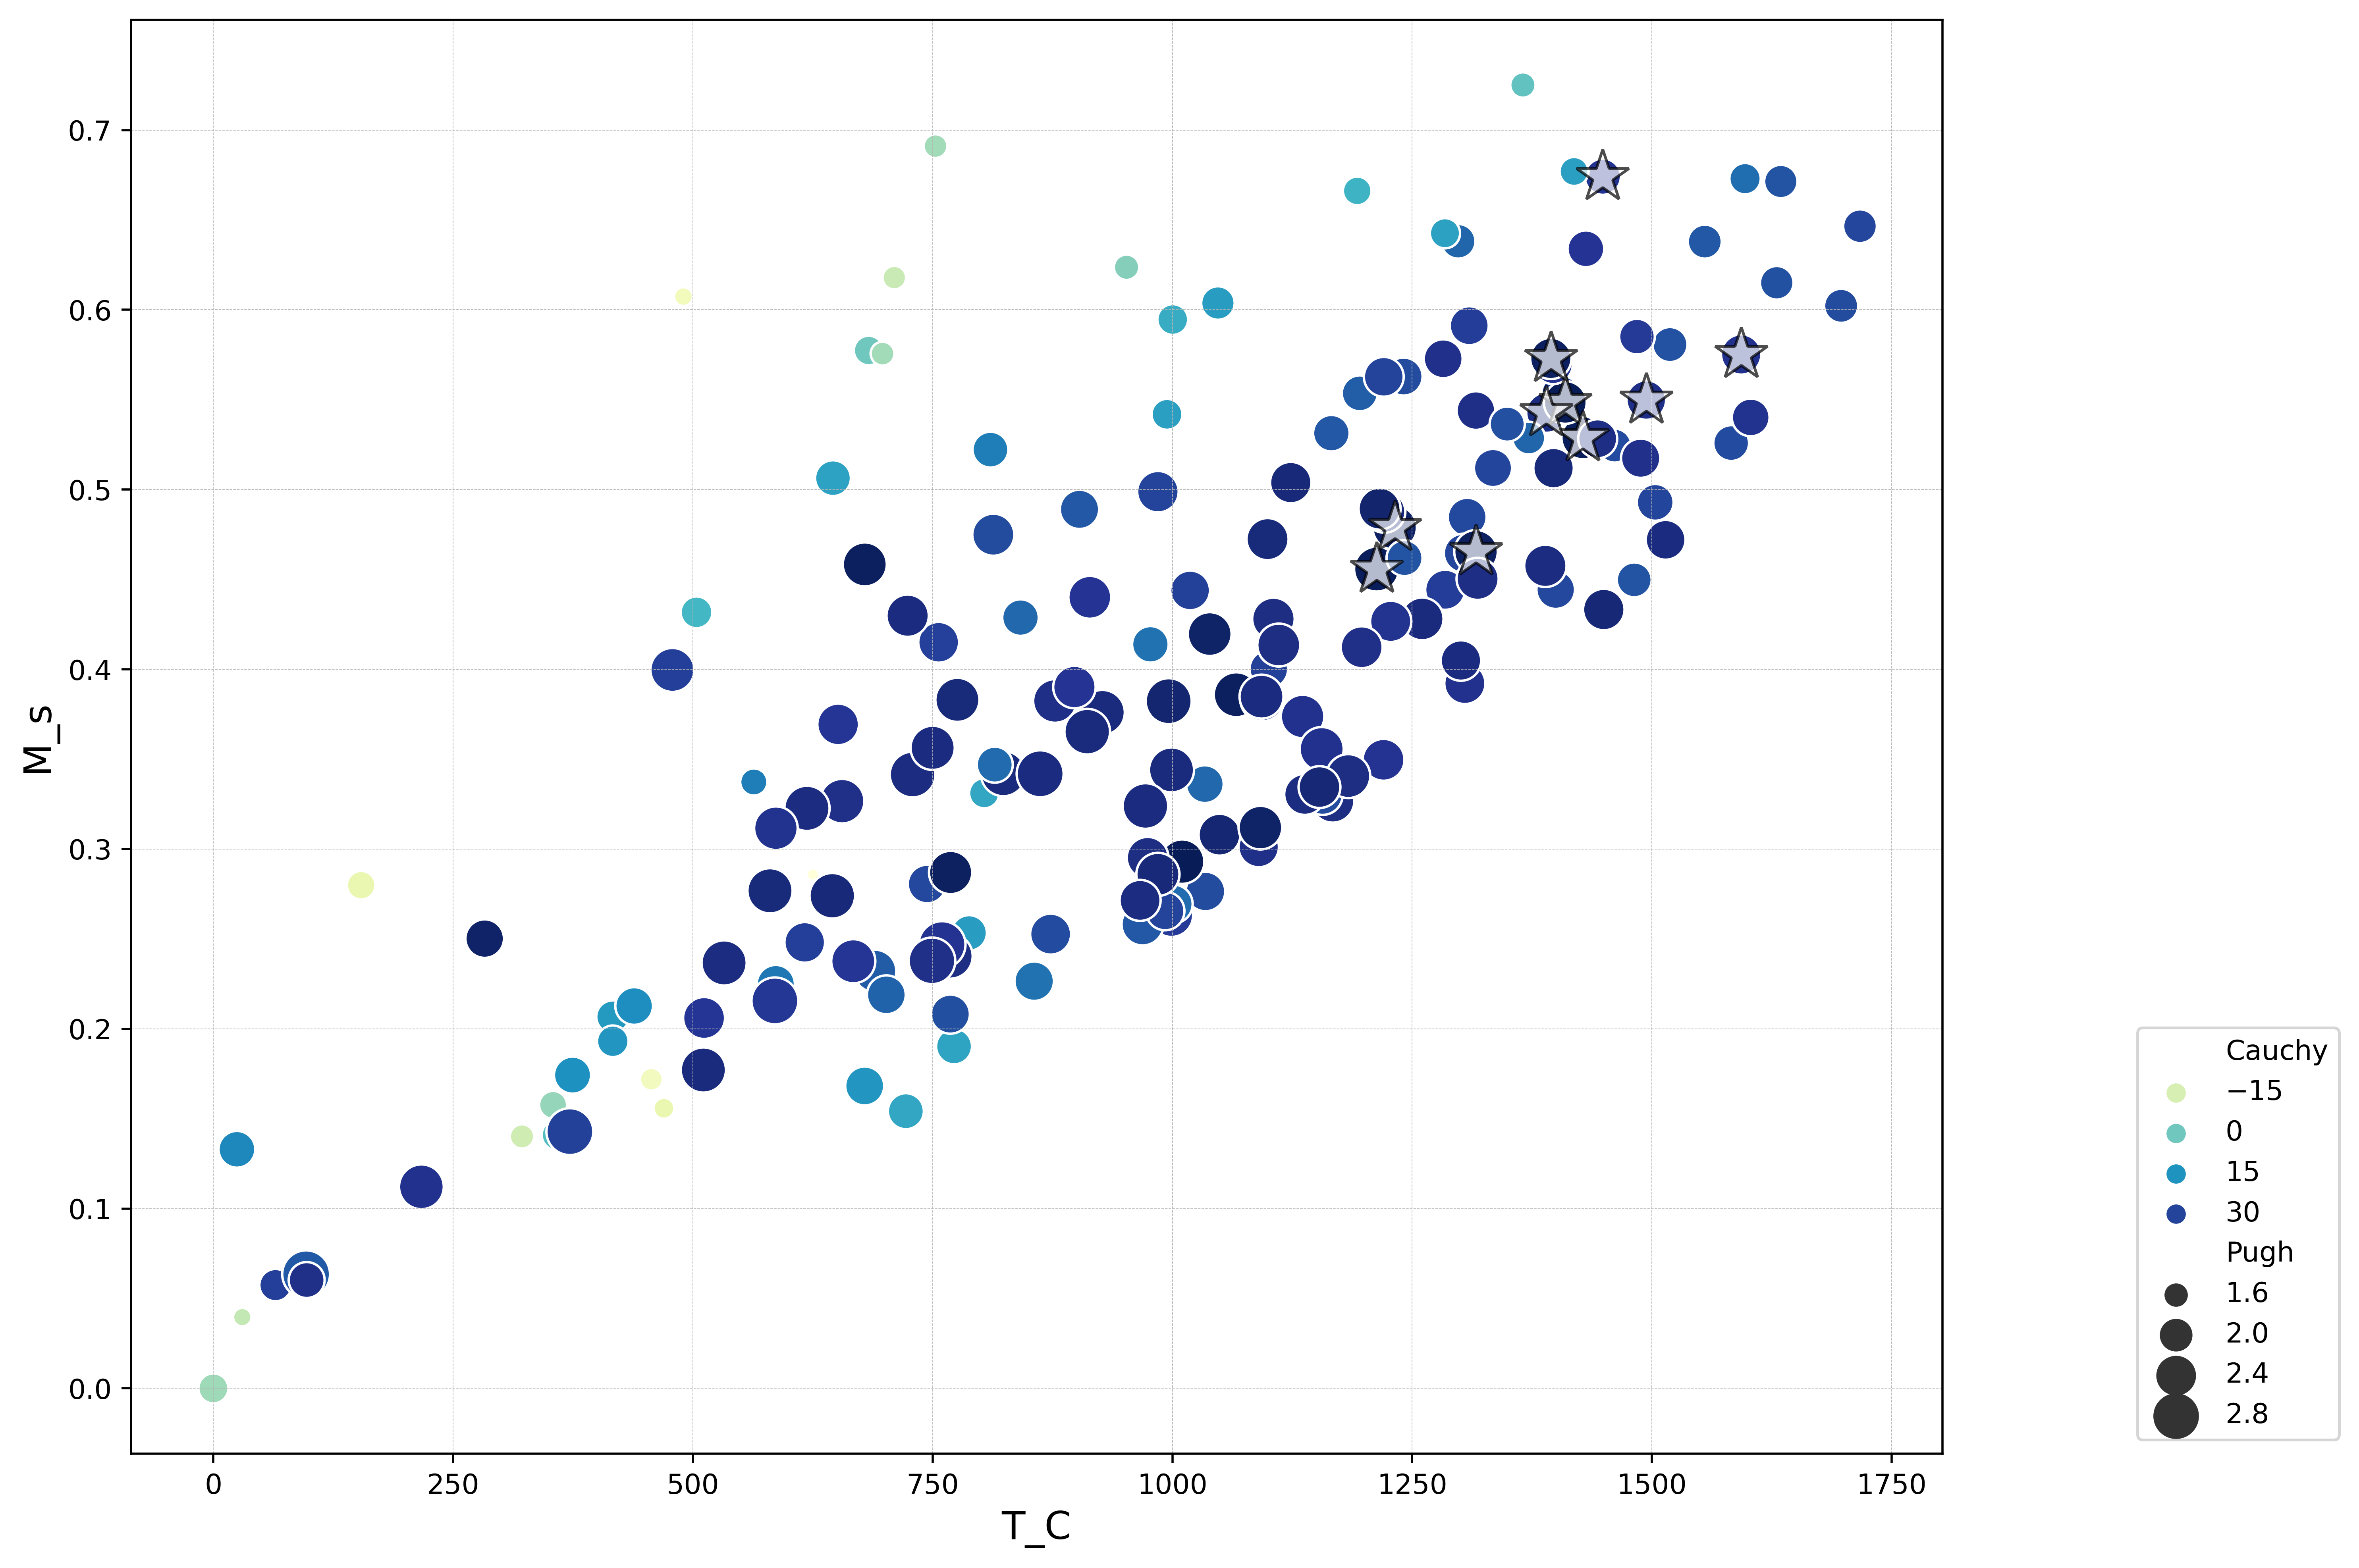

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
data = pd.read_csv('Pareto_data.csv')
pareto_points = data.sort_values(by=['HV'],ascending=False).reset_index(drop=True).head(10)
# 设置图片大小和分辨率
plt.figure(figsize=(12, 8), dpi=500)

# 绘制散点图
ax = sns.scatterplot(
    data=data, 
    x="T_C", 
    # y="Cauchy", 
    y="M_s",
    hue="Cauchy", 
    size="Pugh", 
    # palette='RdYlBu_r',
    palette = 'YlGnBu',
    sizes=(20, 300)
    # hue_norm=(data['M_s'].min() - (data['M_s'].max() - data['M_s'].min()) * 0.1, data['M_s'].max() + (data['M_s'].max() - data['M_s'].min()) * 0.1),  # 增加hue区分度
    # size_norm=(data['Pugh'].min() - (data['Pugh'].max() - data['Pugh'].min()) * 0.1, data['Pugh'].max() + (data['Pugh'].max() - data['Pugh'].min()) * 0.1)  # 增加size区分度

)

# 设置标签
ax.set_xlabel('T_C', fontsize=14)
ax.set_ylabel('M_s', fontsize=14)
ax.grid(linestyle='--', linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)

# 标记Pareto前沿的10个点
# pareto_points = data.nlargest(10, 'Pugh')  # 按Pugh列选择前10个点
for idx, row in pareto_points.iterrows():
    ax.plot(
        row['T_C'], 
        row['M_s'], 
        marker='*', 
        markersize=20, 
        color='white',
        alpha=0.7, 
        markeredgecolor='black', 
        markeredgewidth=1.
    )

# 显示图表
plt.tight_layout()
plt.savefig('BO_mag.png')
plt.show()



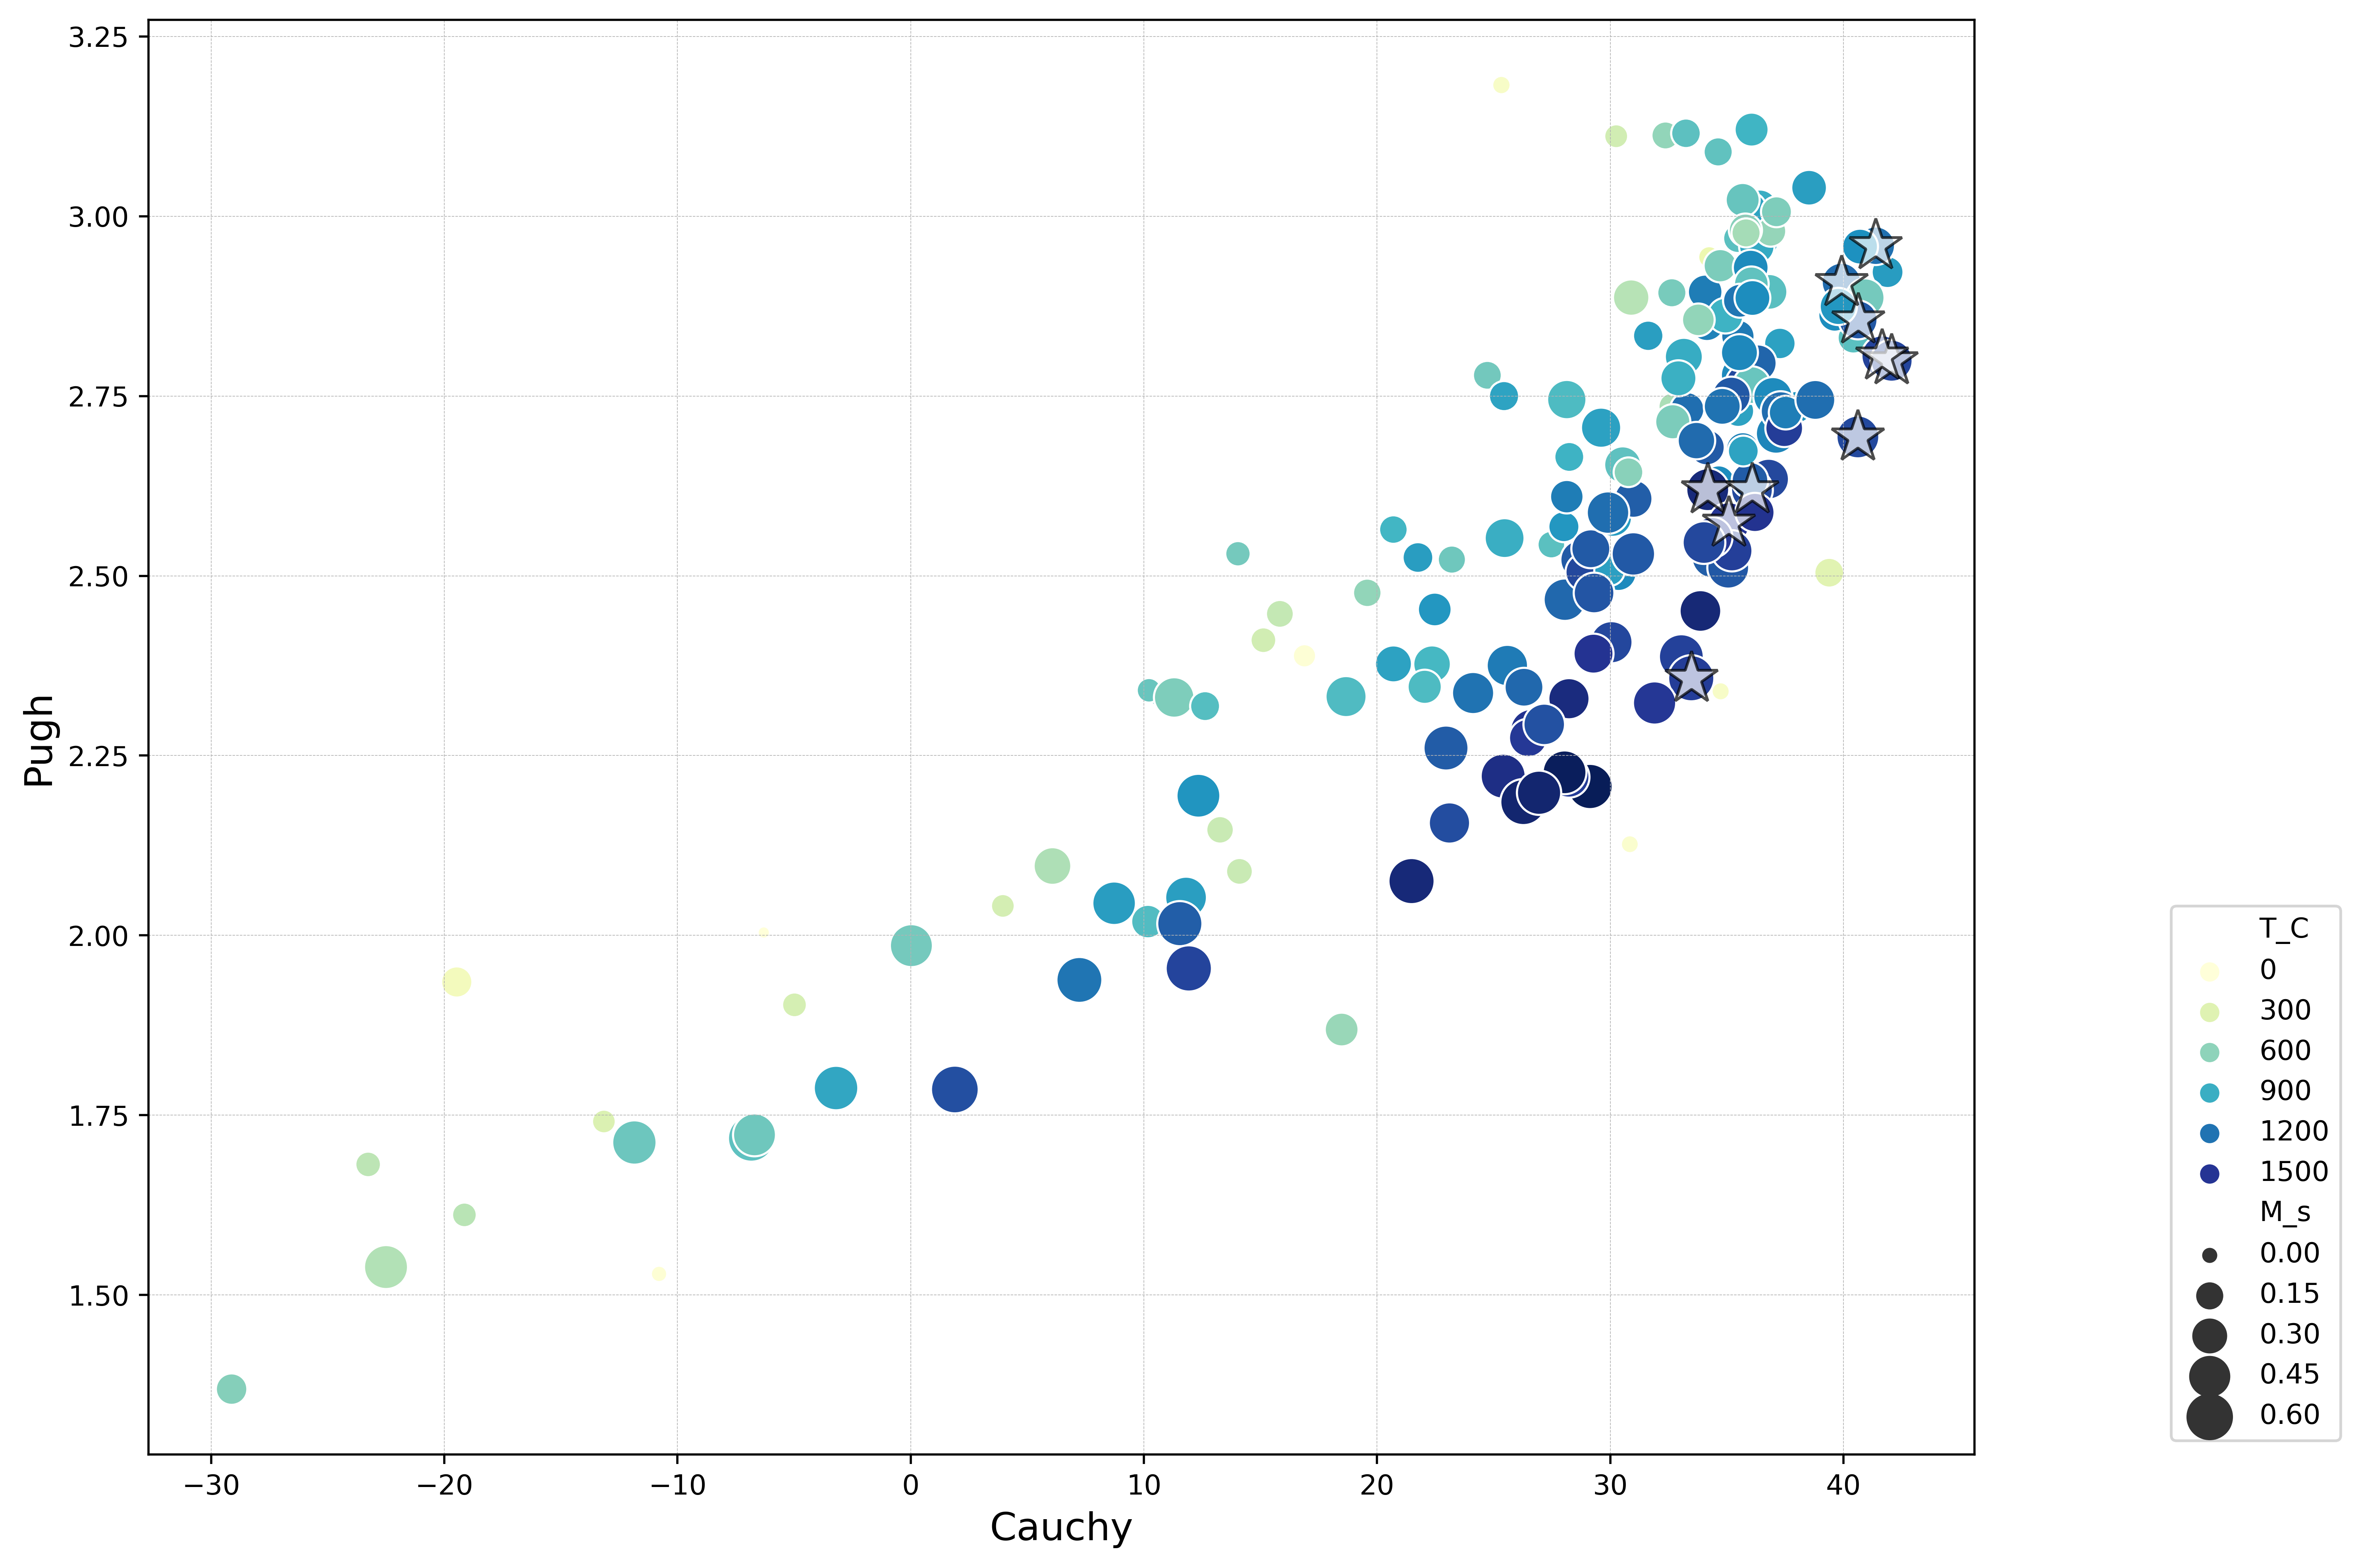

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
data = pd.read_csv('Pareto_data.csv')
pareto_points = data.sort_values(by=['HV'],ascending=False).reset_index(drop=True).head(10)
# 设置图片大小和分辨率
plt.figure(figsize=(12, 8), dpi=500)

# 绘制散点图
ax = sns.scatterplot(
    data=data, 
    x="Cauchy", 
    # y="Cauchy", 
    y="Pugh",
    hue="T_C", 
    size="M_s", 
    # palette='RdYlBu_r',
    palette = 'YlGnBu',
    sizes=(20, 300)
    # hue_norm=(data['M_s'].min() - (data['M_s'].max() - data['M_s'].min()) * 0.1, data['M_s'].max() + (data['M_s'].max() - data['M_s'].min()) * 0.1),  # 增加hue区分度
    # size_norm=(data['Pugh'].min() - (data['Pugh'].max() - data['Pugh'].min()) * 0.1, data['Pugh'].max() + (data['Pugh'].max() - data['Pugh'].min()) * 0.1)  # 增加size区分度

)

# 设置标签
ax.set_xlabel('Cauchy', fontsize=14)
ax.set_ylabel('Pugh', fontsize=14)
ax.grid(linestyle='--', linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)

# 标记Pareto前沿的10个点
# pareto_points = data.nlargest(10, 'Pugh')  # 按Pugh列选择前10个点
for idx, row in pareto_points.iterrows():
    ax.plot(
        row['Cauchy'], 
        row['Pugh'], 
        marker='*', 
        markersize=20, 
        color='white',
        alpha=0.7, 
        markeredgecolor='black', 
        markeredgewidth=1.
    )

# 显示图表
plt.tight_layout()
plt.savefig('BO_mech.png')
plt.show()



         norm_M_s    norm_T_C   norm_Pugh  norm_Cauchy          HV
count  175.000000  175.000000  175.000000   175.000000  175.000000
mean     0.545778    0.567808    0.641383     0.779127    0.382761
std      0.216623    0.227222    0.207209     0.203786    0.248502
min      0.000000    0.000000    0.000000     0.000000    0.000000
25%      0.381496    0.411105    0.530711     0.728163    0.183142
50%      0.551207    0.581890    0.668189     0.844426    0.388734
75%      0.724291    0.752038    0.798322     0.911122    0.560414
max      1.000000    1.000000    1.000000     1.000000    1.000000


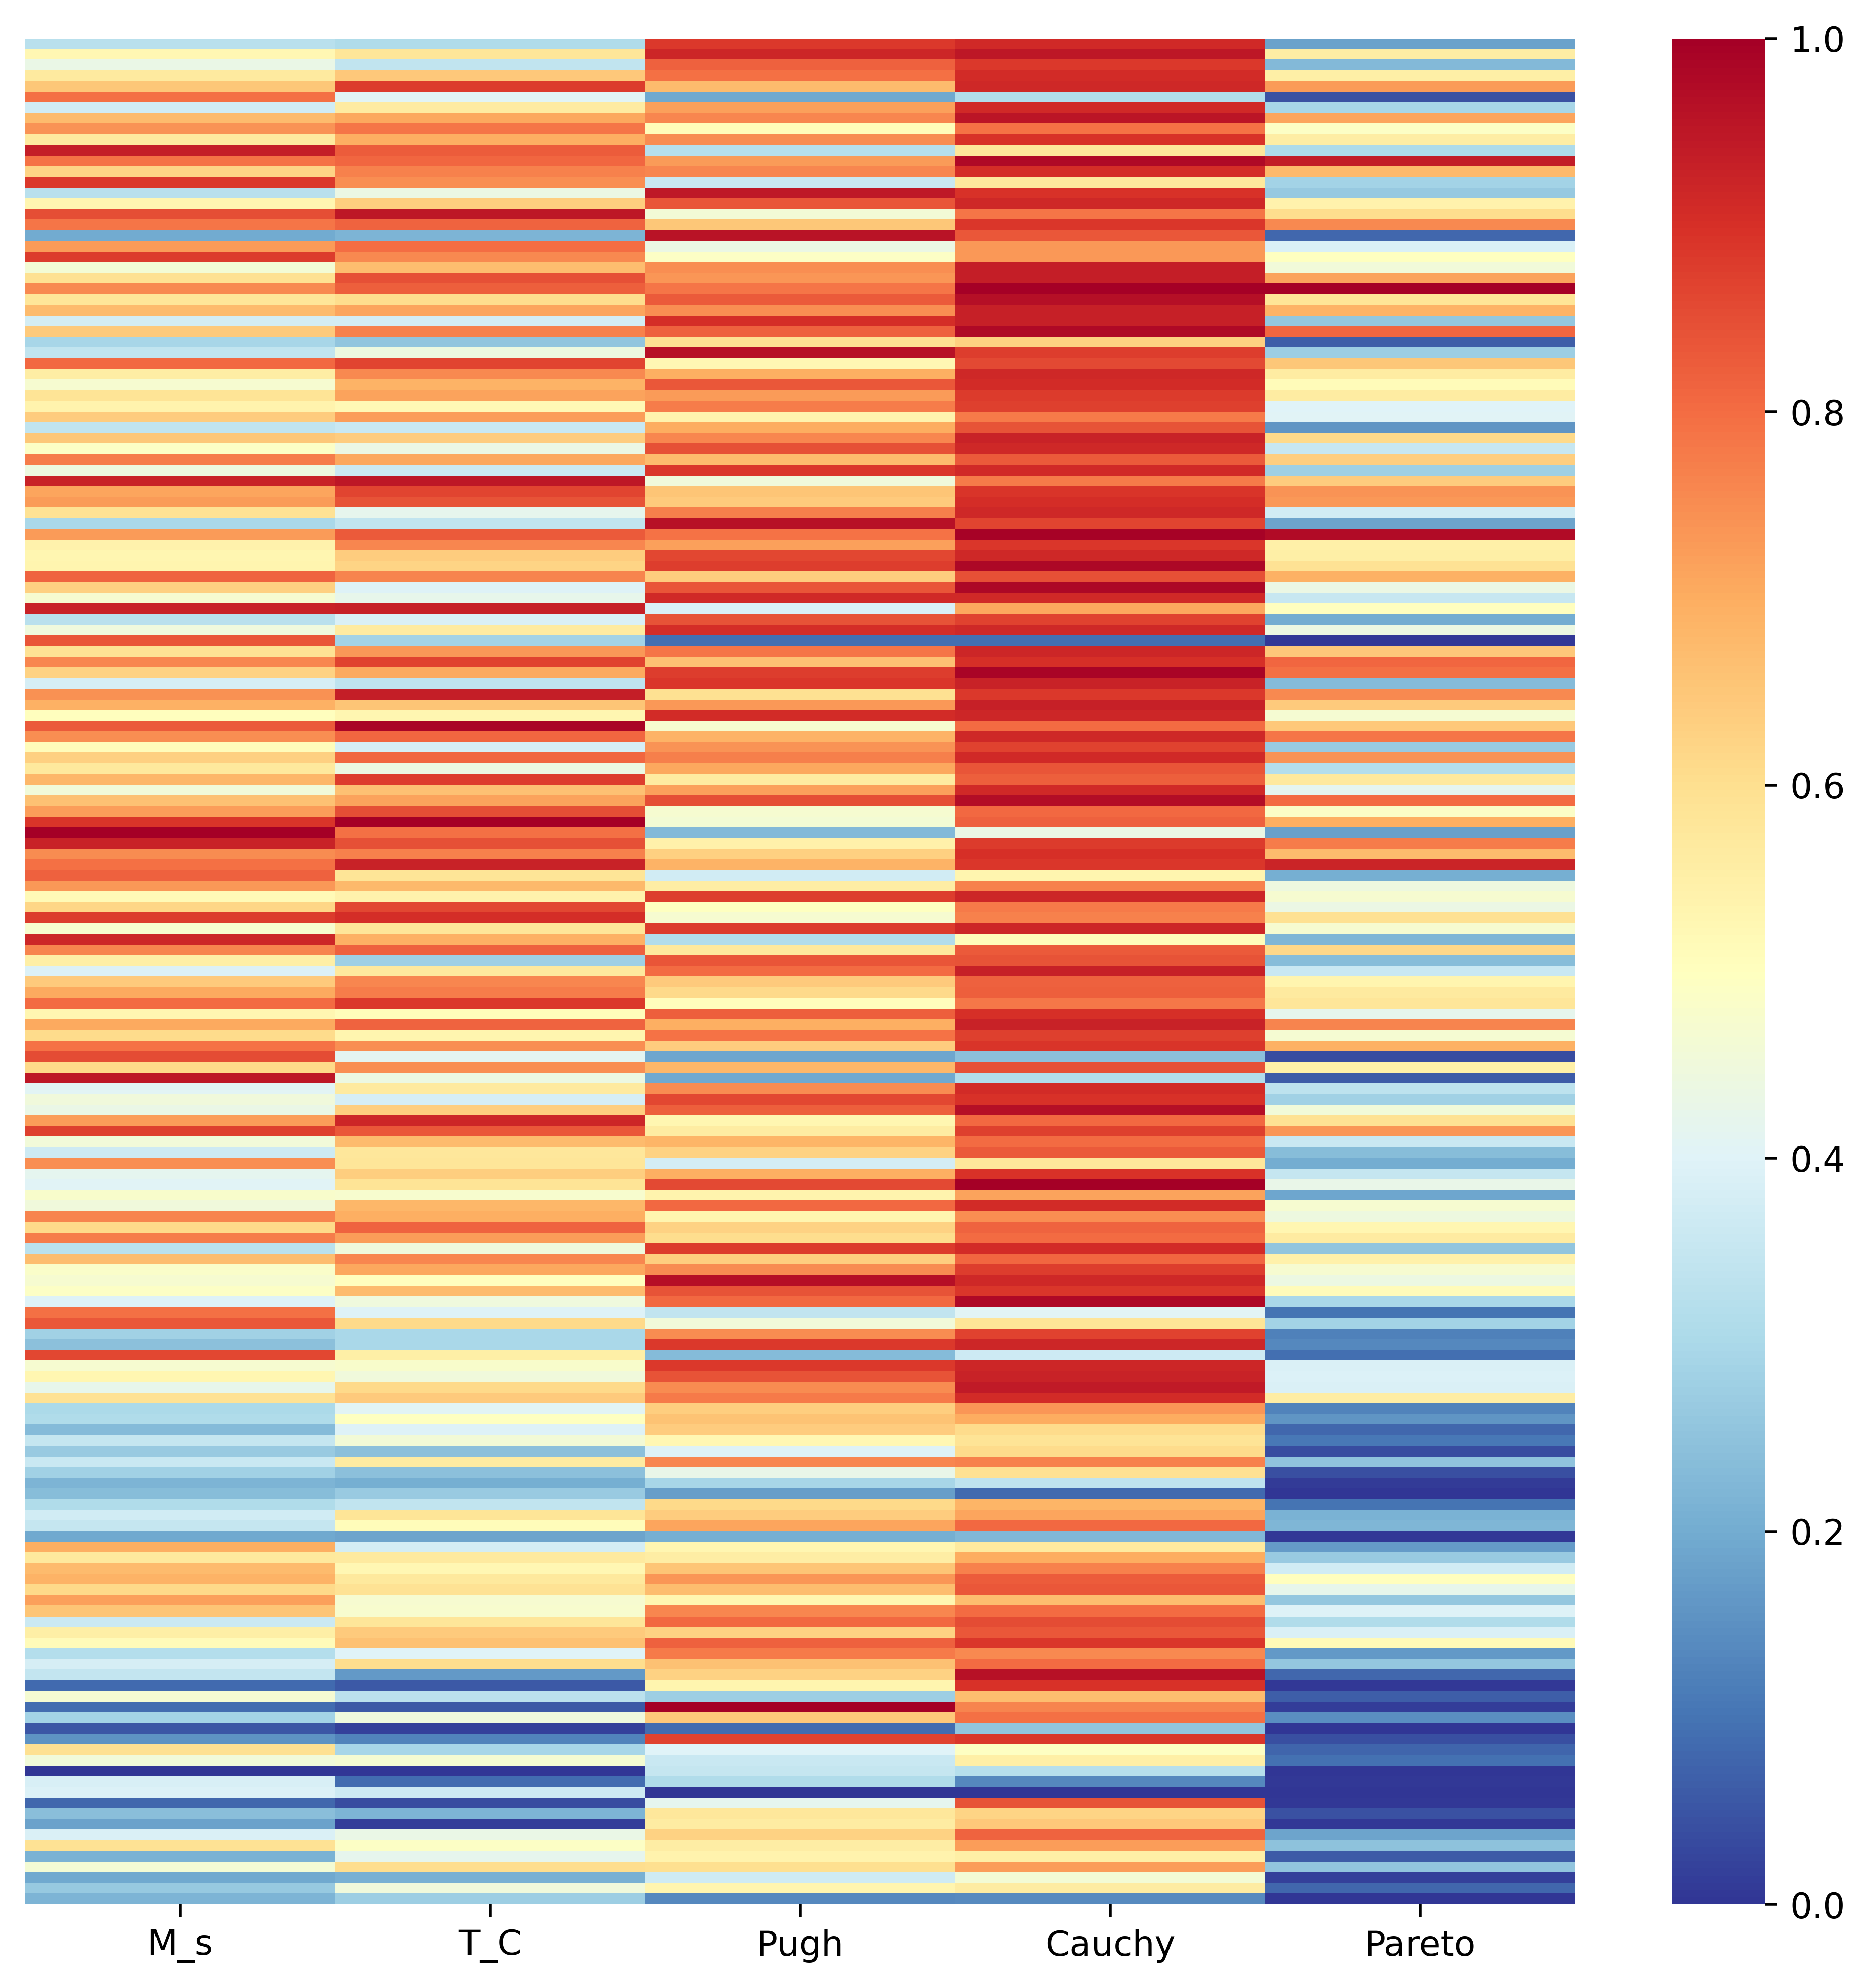

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Pareto_data.csv')
columns = ['M_s', 'T_C','Pugh', 'Cauchy']
# min_values = {col: df[col].min() for col in columns}
# df = df[~df.apply(lambda row: any(row[col] == min_values[col] for col in columns), axis=1)]

# columns_to_normalize_old = ['M_s', 'T_C', 'Pugh', 'Cauchy']
columns_to_normalize = [f"norm_{i}" for i in columns] + ['HV']
df[columns_to_normalize] = df[columns_to_normalize].copy().apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
# # Sorting 
# df = df.sort_values(by=['HV'],ascending=False).reset_index(drop=True)
df = df.iloc[::-1].reset_index(drop=True)

# df['pareto'] = np.sqrt(df['M_s_new']**2 + df['T_C_new']**2 + df['Pugh_new']**2 + df['Cauchy_new']**2)
# df['pareto_new'] = df[['pareto']].copy().apply(
#     lambda x: (x - x.min()) / (x.max() - x.min())
# )
data = df[columns_to_normalize]
print(data.describe())

# columns = ['norm_Pugh']
# max_values = {col: data[col].quantile(0.9) for col in columns}
# data = data[~data.apply(lambda row: any(row[col] >= max_values[col] for col in columns), axis=1)]
# print(data.describe())

fig, ax = plt.subplots(figsize = (8,8), dpi=500)
sns.heatmap(data,               # 鸢尾花数据数组
            cmap = 'RdYlBu_r', # 指定色谱
            ax = ax,           # 指定轴
            # vmax = 1,          # 色谱最大值
            # vmin = 0,          # 色谱最小值
            xticklabels = ['M_s', 'T_C', 'Pugh', 'Cauchy', 'Pareto'],  # 不显示横轴标签
            yticklabels = [],  # 不显示纵轴标签
            cbar = True)       # 显示色谱条
plt.tight_layout()
plt.savefig('BO_iterations.png')
plt.show()
# ## fig.savefig('Figures/鸢尾花数据热图.svg', format='svg')

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
data = pd.read_csv('Pareto_data.csv')
pareto_points = data.sort_values(by=['HV'],ascending=False).reset_index(drop=True).head(20)
# 设置图片大小和分辨率
plt.figure(figsize=(12, 8), dpi=500)

# 绘制散点图
# ax = sns.scatterplot(
#     data=data, 
#     x="T_C", 
#     y="Cauchy", 
#     hue="M_s", 
#     size="Pugh", 
#     # palette='RdYlBu_r',
#     palette = 'YlGnBu',
#     sizes=(20, 300)
#     # hue_norm=(data['M_s'].min() - (data['M_s'].max() - data['M_s'].min()) * 0.1, data['M_s'].max() + (data['M_s'].max() - data['M_s'].min()) * 0.1),  # 增加hue区分度
#     # size_norm=(data['Pugh'].min() - (data['Pugh'].max() - data['Pugh'].min()) * 0.1, data['Pugh'].max() + (data['Pugh'].max() - data['Pugh'].min()) * 0.1)  # 增加size区分度

# )

sns.jointplot(
    data=data,
    x="T_C",
    y="Cauchy",
    kind="scatter",       # 图的类型，可以是 'scatter', 'hex', 'kde', 'reg', 'resid'
    hue="M_s",            # 用于分类的变量
    size="Pugh",          # 用于标记大小的变量
    palette="YlGnBu",     # 调色板
    marginal_kws=dict(bins=30, fill=True)  # 边际图的关键字参数
)

# 设置标签
ax.set_xlabel('T_C', fontsize=14)
ax.set_ylabel('Cauchy', fontsize=14)
ax.grid(linestyle='--', linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)

# # 标记Pareto前沿的10个点
# # pareto_points = data.nlargest(10, 'Pugh')  # 按Pugh列选择前10个点
# for idx, row in pareto_points.iterrows():
#     ax.plot(
#         row['T_C'], 
#         row['Cauchy'], 
#         marker='*', 
#         markersize=20, 
#         color='white',
#         alpha=0.7, 
#         markeredgecolor='black', 
#         markeredgewidth=1.
#     )

# 显示图表
plt.tight_layout()
plt.show()

/home/md88vyxi/.local/lib/python3.6/site-packages/seaborn/axisgrid.py:2182: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

<Figure size 6000x4000 with 0 Axes>